# 02. NESO's benchmark and time alignment

**Where we are:** notebook 01 downloaded NESO's historic demand and settled on the target,
National Demand (`ND`), in MW, for each half-hour settlement period.

**What this notebook does:**

1. Downloads NESO's own day-ahead forecast, which is the benchmark to beat.
2. Builds correct timestamps from settlement periods, including clock-change days.
3. Checks that NESO's "outturn" is the same quantity as `ND`.
4. Measures how accurate NESO's forecast is. That number is the bar for the rest of the project.

**Why bother with a benchmark:** a forecast error of 700 MW means nothing without context.
NESO's published forecast is what the industry actually uses, so beating it, or failing to
and saying by how much, is a meaningful result.

**Background reading**
- [Day Ahead Half Hourly Demand Forecast Performance](https://www.neso.energy/data-portal/day-ahead-half-hourly-demand-forecast-performance): the dataset used here.
- [Settlement period (Elexon glossary)](https://www.elexon.co.uk/glossary/settlement-period/): the half-hour unit used across the GB market.


## Step 1. Set up

**What:** imports, paths and plot style.

**Why:** same layout as notebook 01. Raw downloads go to `data/raw`, cleaned tables to
`data/processed`. Both are kept out of git; the notebooks recreate them.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "lines.linewidth": 2,
})


## Step 2. Download the benchmark

**What:** look up the dataset on NESO's data portal API and save its CSV.

**Why the API:** the file is updated every day, so the notebook should find the current
download link itself rather than hard-code it.

**Note:** the download link redirects, and `requests` follows redirects by default. A plain
`curl` without `-L` saves a "302 Found" HTML page instead of the data, which I found out the
hard way. The check after the download catches that.


In [2]:
API = "https://api.neso.energy/api/3/action/package_show"
BENCHMARK_FILE = RAW / "neso_day_ahead_forecast.csv"

if not BENCHMARK_FILE.exists():
    package = requests.get(
        API, params={"id": "day-ahead-half-hourly-demand-forecast-performance"}, timeout=60
    ).json()["result"]
    resource = package["resources"][0]
    print("resource:", resource["name"])
    response = requests.get(resource["url"], timeout=300)
    response.raise_for_status()
    BENCHMARK_FILE.write_bytes(response.content)

first_line = BENCHMARK_FILE.open(encoding="utf-8-sig").readline()
assert first_line.startswith("Month,Date"), "download is not the expected CSV"
print(f"{BENCHMARK_FILE.name}: {BENCHMARK_FILE.stat().st_size / 1e6:.1f} MB")


neso_day_ahead_forecast.csv: 9.7 MB


## Step 3. First look

**What:** load the file and read the columns.

**Why `encoding="utf-8-sig"`:** the file starts with a byte-order mark, an invisible character
some Windows tools add. Without this, the first column is named `\ufeffMonth` and code that
looks up `Month` fails.

| Column | Meaning |
|---|---|
| `Date`, `Settlement_Period` | the target half-hour, in GB local time |
| `Datetime` | a timestamp label; checked in Step 7 |
| `Demand_Forecast` | NESO's day-ahead forecast, MW |
| `Demand_Outturn` | the demand that actually happened, MW |
| `TRIAD_Avoidance_Estimate` | demand NESO thinks large users cut on likely TRIAD periods (see Step 8) |
| `TRIAD_Avoidance_Corrected_Demand_Outturn` | outturn with that cut added back |
| `APE`, `Absolute_Error` | NESO's own error figures |
| `Publish_Datetime` | when the forecast was published |


In [3]:
bench = pd.read_csv(BENCHMARK_FILE, encoding="utf-8-sig")
print(bench.shape)
print("dates:", bench["Date"].min(), "to", bench["Date"].max())
bench.head()


(98370, 11)
dates: 2021-04-01 to 2026-11-10


,Month,Date,Datetime,Settlement_Period,Demand_Forecast,Demand_Outturn,TRIAD_Avoidance_Estimate,TRIAD_Avoidance_Corrected_Demand_Outturn,APE,Absolute_Error,Publish_Datetime
0,Apr,2021-04-01,2021-04-01T00:30:00Z,1,21570,19970,0,19970,8.0,1600,2021-03-31T09:45:00Z
1,Apr,2021-04-01,2021-04-01T01:00:00Z,2,21130,20030,0,20030,5.5,1100,2021-03-31T09:45:00Z
2,Apr,2021-04-01,2021-04-01T01:30:00Z,3,21272,20499,0,20499,3.8,773,2021-03-31T09:45:00Z
3,Apr,2021-04-01,2021-04-01T02:00:00Z,4,21600,20940,0,20940,3.2,660,2021-03-31T09:45:00Z
4,Apr,2021-04-01,2021-04-01T02:30:00Z,5,21478,20682,0,20682,3.8,796,2021-03-31T09:45:00Z


## Step 4. Data checks

**What:** look for missing values, repeated half-hours and days with the wrong number of periods.

**Why:** a day has 48 periods, or 46 and 50 on the spring and autumn clock-change days (see
notebook 01). Anything else means a fault in the file or a day that is not finished yet.


In [4]:
KEY = ["Date", "Settlement_Period"]
print("missing values:", int(bench.isna().sum().sum()))

repeated = bench[bench.duplicated(KEY, keep=False)]
print("rows sharing a date and period:", len(repeated))
print(repeated[KEY + ["Datetime", "Demand_Outturn"]].to_string())


missing values: 0
rows sharing a date and period: 8
             Date  Settlement_Period              Datetime  Demand_Outturn
10225  2021-10-31                  4  2021-10-31T01:00:00Z           21087
10226  2021-10-31                  4  2021-10-31T01:00:00Z           21087
10227  2021-10-31                  5  2021-10-31T01:30:00Z           20743
10228  2021-10-31                  5  2021-10-31T01:30:00Z           20743
27697  2022-10-30                  2  2022-10-30T01:00:00Z           18302
27698  2022-10-30                  2  2022-10-30T01:00:00Z           18302
27699  2022-10-30                  3  2022-10-30T01:30:00Z           17778
27700  2022-10-30                  3  2022-10-30T01:30:00Z           17778


In [5]:
periods = bench.groupby("Date")["Settlement_Period"].agg(["count", "max"])
print(periods["count"].value_counts().sort_index().to_string())
print()
print(periods[periods["count"] != 48].to_string())


count
18       1
46       5
48    2039
50       5

            count  max
Date                  
2021-10-31     50   50
2022-03-27     46   46
2023-03-26     46   46
2023-10-29     50   50
2024-03-31     46   46
2024-10-27     50   50
2025-03-30     46   46
2025-10-26     50   50
2026-03-29     46   46
2026-10-25     50   50
2026-11-10     18   18


**Found:**

- No missing values.
- **Two autumn clock-change days are mislabelled.** On 2021-10-31 and 2022-10-30, periods 2
  and 3 are missing and periods 4 and 5 appear twice with the same outturn. The `Datetime`
  values (01:00, 01:30 twice) suggest the rows were matched on clock time, which repeats when
  the clocks go back. There is no safe way to tell which row is which, so I drop all of them.
  That loses 8 rows out of about 98,000.
- The other clock-change days have the right 46 or 50 periods.
- The last day is part-way through, because NESO adds outturn as the day goes on. I keep only
  complete days.


In [6]:
bench = bench[~bench.duplicated(KEY, keep=False)].copy()

per_day = bench.groupby("Date")["Settlement_Period"]
complete = (per_day.transform("count") == per_day.transform("max")) & (per_day.transform("max") >= 46)
print("dropped (incomplete days):", sorted(bench.loc[~complete, "Date"].unique()))
bench = bench[complete].reset_index(drop=True)
print(bench.shape, bench["Date"].min(), "to", bench["Date"].max())


dropped (incomplete days): ['2021-10-31', '2022-10-30', '2026-11-10']
(98254, 11) 2021-04-01 to 2026-11-09


## Step 5. When does NESO publish?

**What:** look at `Publish_Datetime`.

**Why:** this sets the information cut-off for our own forecast. If NESO publishes at 09:45 the
day before, our model must use only data available by then. Using anything later would give
us an unfair advantage and make the comparison worthless.


In [7]:
published = pd.to_datetime(bench["Publish_Datetime"], utc=True)
target_day = pd.to_datetime(bench["Date"]).dt.tz_localize("UTC")
hours_before = (target_day - published).dt.total_seconds() / 3600

print("published on the day before:", bool(((hours_before > 0) & (hours_before < 24)).all()))
print()
print(published.dt.strftime("%H:%M").groupby(published.dt.year).value_counts().rename("rows").to_string())


published on the day before: True

Publish_Datetime  Publish_Datetime
2021              09:45               10224
                  08:45                2976
2022              09:45               10368
                  08:45                7102
2023              09:45               10418
                  08:45                7102
2024              09:45               10082
                  08:45                7486
2025              09:45                8832
                  09:33                4466
                  08:45                4222
2026              09:33                8926
                  08:33                5666
                  10:03                 192
                  09:03                  96
                  10:33                  96


**Found:** every forecast is published on the day before the target day. The recorded times
run from 08:33 to 10:33, with two or more different times in every year. The values end in `Z`
(UTC), but Step 7 shows that the `Z` on `Datetime` is wrong, so I do not trust it here either.

**Decision:** our forecast origin is **08:30 UTC on the day before**, earlier than every
published time under any reading of the timestamps. If anything, this gives NESO a small
information advantage, which is the safe direction for an honest comparison.


In [8]:
FORECAST_ORIGIN_UTC = "08:30"  # on the day before the target day; used from notebook 04


## Step 6. Timestamps from settlement periods

**What:** turn each (date, period) pair into a UTC timestamp for the start of the half-hour.

**Why UTC:** local time repeats an hour in October and skips one in March. UTC never does, so
it is the safe key for joining weather data and for sorting. Settlement period 1 starts at local
midnight, and each period is 30 minutes, so:

`start (UTC) = local midnight in Europe/London + (period - 1) × 30 minutes`

Adding the minutes to a timezone-aware midnight counts real elapsed time. That is exactly what
makes 46 and 50 period days come out right with no special cases.

**Further reading**
- [pandas `tz_localize`](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.tz_localize.html)
- [Python `zoneinfo`](https://docs.python.org/3/library/zoneinfo.html), which holds the clock-change rules
- [British Summer Time](https://en.wikipedia.org/wiki/British_Summer_Time): when the clocks change


In [9]:
def period_start_utc(dates, periods):
    """UTC start of each settlement period, given local dates and period numbers."""
    local_midnight = pd.to_datetime(dates).dt.tz_localize("Europe/London")
    offset = pd.to_timedelta((periods - 1) * 30, unit="min")
    return (local_midnight + offset).dt.tz_convert("UTC")


bench["start_utc"] = period_start_utc(bench["Date"], bench["Settlement_Period"])


**Test:** if the formula is right, then on every day

1. the periods are exactly 30 minutes apart, and
2. the last period ends at the next local midnight.

Both are checked over every day in the file, not just a few examples.


In [10]:
half_hour = pd.Timedelta(minutes=30)

gaps = bench.groupby("Date")["start_utc"].diff().dropna()
assert (gaps == half_hour).all(), "periods are not 30 minutes apart"

last = bench.groupby("Date")["start_utc"].max() + half_hour
next_midnight = (pd.to_datetime(last.index) + pd.Timedelta(days=1)).tz_localize("Europe/London")
assert (last.values == next_midnight.tz_convert("UTC").values).all(), "day does not end at midnight"

print("checks passed on", bench["Date"].nunique(), "days")


checks passed on 2047 days


In [11]:
example_days = ["2024-03-31", "2024-10-27"]
cols = ["Date", "Settlement_Period", "start_utc", "Datetime"]
for day in example_days:
    rows = bench[bench["Date"] == day]
    print(f"{day}: {len(rows)} periods")
    print(rows[cols].head(5).to_string(index=False))
    print()


2024-03-31: 46 periods
      Date  Settlement_Period                 start_utc             Datetime
2024-03-31                  1 2024-03-31 00:00:00+00:00 2024-03-31T00:30:00Z
2024-03-31                  2 2024-03-31 00:30:00+00:00 2024-03-31T02:00:00Z
2024-03-31                  3 2024-03-31 01:00:00+00:00 2024-03-31T02:30:00Z
2024-03-31                  4 2024-03-31 01:30:00+00:00 2024-03-31T03:00:00Z
2024-03-31                  5 2024-03-31 02:00:00+00:00 2024-03-31T03:30:00Z

2024-10-27: 50 periods
      Date  Settlement_Period                 start_utc             Datetime
2024-10-27                  1 2024-10-26 23:00:00+00:00 2024-10-27T00:30:00Z
2024-10-27                  2 2024-10-26 23:30:00+00:00 2024-10-27T01:00:00Z
2024-10-27                  3 2024-10-27 00:00:00+00:00 2024-10-27T01:30:00Z
2024-10-27                  4 2024-10-27 00:30:00+00:00 2024-10-27T01:00:00Z
2024-10-27                  5 2024-10-27 01:00:00+00:00 2024-10-27T01:30:00Z



## Step 7. The `Datetime` column is not UTC

**What:** compare NESO's `Datetime` labels with the timestamps from Step 6.

**Found:** above, on 2024-03-31 (46 periods) `Datetime` jumps from 00:30 to 02:00, and on
2024-10-27 (50 periods) it shows 01:00 twice. A UTC clock never jumps or repeats. So despite the
`Z`, the column is **local clock time at the end of each period**. On normal days that looks
fine for half the year and is an hour out for the other half.

The code below checks this reading across the whole file.


In [12]:
end_local = (bench["start_utc"] + half_hour).dt.tz_convert("Europe/London")
label = pd.to_datetime(bench["Datetime"].str.rstrip("Z"))
matches_local_end = end_local.dt.tz_localize(None) == label

print(f"label = local end of period: {matches_local_end.mean():.4f} of rows")
mismatch_days = bench.loc[~matches_local_end, "Date"].unique()
print("days where it does not hold:", list(mismatch_days))
print(bench.loc[bench["Date"].isin(mismatch_days), cols].head(6).to_string(index=False))


label = local end of period: 0.9986 of rows
days where it does not hold: ['2025-10-26', '2026-03-29', '2026-10-25']
      Date  Settlement_Period                 start_utc             Datetime
2025-10-26                  1 2025-10-25 23:00:00+00:00 2025-10-26T00:30:00Z
2025-10-26                  2 2025-10-25 23:30:00+00:00 2025-10-26T01:00:00Z
2025-10-26                  3 2025-10-26 00:00:00+00:00 2025-10-26T01:30:00Z
2025-10-26                  4 2025-10-26 00:30:00+00:00 2025-10-26T02:00:00Z
2025-10-26                  5 2025-10-26 01:00:00+00:00 2025-10-26T02:30:00Z
2025-10-26                  6 2025-10-26 01:30:00+00:00 2025-10-26T03:00:00Z


**Found:** the reading holds for 99.86% of rows. The exceptions are the three most recent
clock-change days (2025-10-26, 2026-03-29, 2026-10-25), where the labels run straight through
as if the day had 48 periods. So NESO's labelling has changed over time as well.

**Decision:** never join on `Datetime`. Join on date and settlement period, then use `start_utc`.


## Step 8. Is NESO's outturn the same as `ND`?

**What:** join the benchmark to the historic data from notebook 01 and compare `Demand_Outturn`
with `ND`.

**Why:** our model is trained on `ND`, back to 2018. If NESO's outturn were a different
quantity, the comparison at the end would be unfair to one side.

The historic files are read the same way as in notebook 01 (with their mixed date formats).
That code moves into a shared module on Day 9.


In [13]:
DATE_FORMATS = ("%d-%b-%Y", "%d-%b-%y", "%Y-%m-%d")


def parse_settlement_dates(values):
    for date_format in DATE_FORMATS:
        parsed = pd.to_datetime(values, format=date_format, errors="coerce")
        if parsed.notna().all():
            return parsed
    raise ValueError(f"No known date format fits, for example {values.iloc[0]!r}")


frames = []
for path in sorted(RAW.glob("demanddata_*.csv")):
    frame = pd.read_csv(path)
    frame["SETTLEMENT_DATE"] = parse_settlement_dates(frame["SETTLEMENT_DATE"])
    frames.append(frame)
demand = pd.concat(frames, ignore_index=True)
demand["Date"] = demand["SETTLEMENT_DATE"].dt.strftime("%Y-%m-%d")
demand = demand.rename(columns={"SETTLEMENT_PERIOD": "Settlement_Period"})
demand["start_utc"] = period_start_utc(demand["Date"], demand["Settlement_Period"])
print(demand.shape, demand["Date"].min(), "to", demand["Date"].max())


(154270, 25) 2018-01-01 to 2026-10-19


In [14]:
joined = bench.merge(demand[KEY + ["ND", "TSD"]], on=KEY, how="inner")
print(f"matched {len(joined):,} of {len(bench):,} benchmark rows (historic data ends earlier)")

joined["outturn_minus_nd"] = joined["Demand_Outturn"] - joined["ND"]
joined["summer_time"] = joined["start_utc"].dt.tz_convert("Europe/London").map(lambda t: bool(t.dst()))
print(f"exactly equal: {(joined['outturn_minus_nd'] == 0).mean():.3f}")
print(f"equal to TSD:  {(joined['Demand_Outturn'] == joined['TSD']).mean():.3f}")
print()
print(joined.groupby("summer_time")["outturn_minus_nd"].describe().round(0).to_string())


matched 97,244 of 98,254 benchmark rows (historic data ends earlier)
exactly equal: 0.011
equal to TSD:  0.000

               count  mean   std     min    25%   50%   75%     max
summer_time                                                        
False        36196.0 -93.0  58.0 -1575.0 -124.0 -99.0 -68.0   974.0
True         61048.0   4.0  43.0 -1575.0  -16.0   0.0  22.0  1093.0


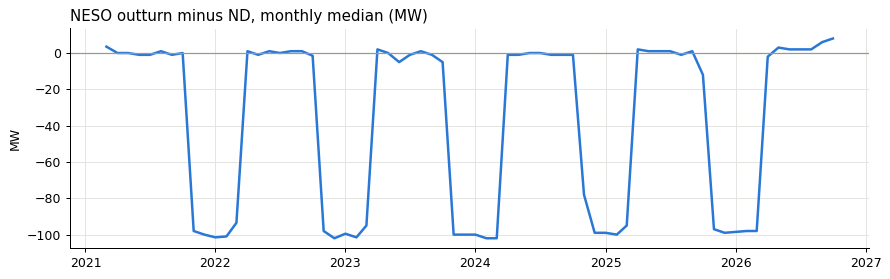

In [15]:
monthly_gap = joined.groupby(joined["start_utc"].dt.tz_convert(None).dt.to_period("M"))["outturn_minus_nd"].median()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(monthly_gap.index.to_timestamp(), monthly_gap.values, color=BLUE)
ax.axhline(0, color="#999990", linewidth=1)
ax.set_title("NESO outturn minus ND, monthly median (MW)", loc="left")
ax.set_ylabel("MW")
fig.tight_layout()
plt.show()


**Found:**

- `Demand_Outturn` is **not identical** to `ND` and never equals `TSD`, but it is close.
- In British Summer Time the median gap is 0 MW. In winter (GMT) the outturn sits about
  100 MW below `ND`. Notebook 01 found that NESO assumes 500 MW of station load in summer and
  600 MW in winter, so a 100 MW step at the clock change points to the benchmark using a
  different station-load figure. I have not found this documented.
- The remaining scatter (tens of MW) is most likely metering revisions between the two
  publications.
- The gap is about 0.3% of demand. Step 11 checks whether it changes NESO's score.
- **Day 1's open question:** notebook 01 found that from mid-June 2026 `TSD` no longer equals
  `ND` plus station load, pumping and exports. The benchmark still agrees with `ND` over those
  months (the line above stays flat). So `ND` is fine and the change is in how `TSD` is
  reported. We do not use `TSD`, so this does not affect the project.


**TRIADs.** The TRIADs are the three half-hours of highest GB demand between November and
February, at least ten days apart. Some network charges have been set by demand in those
periods, so large users cut consumption when a TRIAD looks likely. NESO estimates that cut and
publishes a corrected outturn.

**Why it matters here:** on those periods NESO might score itself against the corrected
outturn. The check below tests that against the `Absolute_Error` column.

**Further reading:** [TRIAD (Elexon glossary)](https://www.elexon.co.uk/glossary/triad/),
[NESO TNUoS charges and TRIAD data](https://www.neso.energy/industry-information/charging/tnuos-charges)


In [16]:
error = bench["Demand_Forecast"] - bench["Demand_Outturn"]
differs = (error.abs() - bench["Absolute_Error"]).abs() > 1
triad = bench["TRIAD_Avoidance_Estimate"] != 0

print("rows where NESO's Absolute_Error differs:", int(differs.sum()))
print("of which TRIAD-adjusted:", int((differs & triad).sum()))
print()
print(bench[triad].groupby(bench["Date"].str[:4])["Date"].nunique().rename("days with a TRIAD adjustment").to_string())
print("last TRIAD adjustment:", bench.loc[triad, "Date"].max())


rows where NESO's Absolute_Error differs: 313
of which TRIAD-adjusted: 313

Date
2021    14
2022    19
2023    16
2024    13
2025     7
last TRIAD adjustment: 2025-02-11


**Found:** all 313 rows where NESO's `Absolute_Error` differs from forecast minus outturn are
TRIAD-adjusted rows, so NESO does score itself against the corrected outturn there. Adjustments
appear each winter from 2021/22 to 2024/25 and stop after February 2025; winter 2025/26 has none.
They cover a small share of the test window, so Step 11 uses the plain outturn and Day 8 checks
whether those periods change the comparison.


## Step 9. Save clean tables

**What:** save the cleaned benchmark and the full historic demand table as Parquet.

**Why Parquet:** it keeps column types, including the timezone on `start_utc`, and reads far
faster than CSV. Later notebooks start from these files instead of repeating Steps 2 to 8.

**Further reading:** [Apache Parquet overview](https://parquet.apache.org/docs/overview/)


In [17]:
bench_out = bench[[
    "start_utc", "Date", "Settlement_Period", "Demand_Forecast", "Demand_Outturn",
    "TRIAD_Avoidance_Estimate", "TRIAD_Avoidance_Corrected_Demand_Outturn", "Publish_Datetime",
]]
bench_out.to_parquet(PROCESSED / "neso_benchmark.parquet", index=False)

demand_out = demand.drop(columns=["SETTLEMENT_DATE"]).sort_values("start_utc")
demand_out.to_parquet(PROCESSED / "demand.parquet", index=False)

for name in ["neso_benchmark.parquet", "demand.parquet"]:
    back = pd.read_parquet(PROCESSED / name)
    print(name, back.shape, back["start_utc"].dtype)


neso_benchmark.parquet (98254, 8) datetime64[ns, UTC]
demand.parquet (154270, 24) datetime64[ns, UTC]
